# UKF for a mass-spring-damper system

A self-contained, executed Python tutorial following **Algorithm 2.1** paper by van der Merwe and Wan.

You will construct the MSD model, derive the sigma-point moments, follow each prediction/update equation, inspect one numerical iteration, reconstruct position and unmeasured velocity, and validate the complete result against an independent linear Kalman filter. The companion MATLAB script uses the same benchmark and equation-linked comments.

The source notation is retained: $\mathbf R^v$ and $\mathbf R^n$ denote noise covariances, $W_i^{(m)}$ and $W_i^{(c)}$ denote distinct weights, and $\mathbf P=\mathbf S\mathbf S^T$ denotes a column square root.


## 1. The mass-spring-damper model and the paper's symbols

Write the mechanical equation using $p$ for position and $d$ for velocity, so the paper's $v_k$ can continue to mean **process noise**:

$$m\ddot p+b\dot p+k_rp=u,\qquad
\mathbf{x}=\begin{bmatrix}p\\d\end{bmatrix},\qquad
\dot{\mathbf{x}}=A\mathbf{x}+Bu,$$
$$A=\begin{bmatrix}0&1\\-k_r/m&-b/m\end{bmatrix},\quad
B=\begin{bmatrix}0\\1/m\end{bmatrix}.$$

Both tutorials and both MATLAB scripts use $m=1$ kg, $b=0.5$ N s/m, $k_r=1.9$ N/m, $T_s=0.01$ s, $u_k=0.1\sin(kT_s)$ N, and a 10 s run.

The example uses **forward Euler**, not exact zero-order hold. Applying $\mathbf{x}_{k+1}\approx\mathbf{x}_k+T_s\dot{\mathbf{x}}_k$ gives
$$A_d=I+T_sA,\qquad B_d=T_sB,\qquad
\mathbf{F}[\mathbf{x}_k,u_k]=A_d\mathbf{x}_k+B_du_k.$$
The paper's Eqs. (1)-(2) become
$$\mathbf{x}_{k+1}=\mathbf{F}[\mathbf{x}_k,u_k]+\mathbf{v}_k,\qquad
y_k=\mathbf{H}[\mathbf{x}_k]+n_k,\qquad \mathbf{H}[\mathbf{x}]=[1\;0]\mathbf{x}.$$

The deterministic function $\mathbf{F}$ does not draw random numbers. Noise enters the simulated plant separately, and its covariance enters the filter through $\mathbf{R}^v$ and $\mathbf{R}^n$.

| Paper | Code | Meaning and shape |
|---|---|---|
| $L$ | `L` | State dimension, 2 |
| $\hat{\mathbf{x}}_k$ | `x_hat[:, k]` | Posterior mean, `(2,)` |
| $\hat{\mathbf{x}}_k^-$ | `x_hat_minus` | Predicted mean, `(2,)` |
| $\mathcal{X}_{k-1}$ | `X` | Prior sigma points, `(2, 5)` |
| $\mathcal{X}_{k\mid k-1}$ | `X_minus` | Propagated sigma points, `(2, 5)` |
| $\mathcal{Y}_{k\mid k-1}$ | `Y_minus` | Observation sigma points, `(1, 5)` |
| $\hat y_k^-$ | `y_hat_minus` | Predicted position, `(1,)` |
| $\mathbf{P}_{\tilde y_k\tilde y_k}$ | `P_yy` | Innovation covariance, `(1, 1)` |
| $\mathbf{P}_{x_ky_k}$ | `P_xy` | Cross covariance, `(2, 1)` |
| $\mathbf{K}_k$ | `K` | Kalman gain, `(2, 1)` |
| $\mathbf{R}^v$ | `Rv` | Discrete process-noise covariance, `(2, 2)` |
| $\mathbf{R}^n$ | `Rn` | Position-noise covariance, `(1, 1)` |

Python column `k` represents paper time $k$; MATLAB column `k+1` represents the same time. The central sigma point is Python column 0 and MATLAB column 1. The physical spring stiffness is `kr`, leaving `k` for the filter time index.


In [9]:
import numpy as np  # Numerical arrays for the paper's vectors and matrices.
import matplotlib.pyplot as plt  # Tutorial figures; not part of the filter recursion.
from scipy.linalg import solve_triangular  # Section 3: factor-based linear solves.
np.set_printoptions(precision=8, suppress=True)  # Tutorial output formatting.


## 2. Noise timing and initialization

The demonstration uses acceleration noise $a_k\sim\mathcal{N}(0,w^2)$ with $w=10^{-4}$ m/s$^2$. Euler integration gives
$$\mathbf v_k=\begin{bmatrix}0\\T_sa_k\end{bmatrix},\qquad
\mathbf R^v=\begin{bmatrix}0&0\\0&T_s^2w^2\end{bmatrix},\qquad
\sqrt{\mathbf R^v}=\begin{bmatrix}0&0\\0&T_sw\end{bmatrix}.$$
With measurement standard deviation $v=10^{-3}$ m, $\mathbf R^n=[v^2]=[10^{-6}]$ m$^2$. The lowercase code names `w` and `v` are simulation standard deviations, not the paper's noise vectors. Both filters use fixed noise covariances.

Why this timing? Algorithms 2.1 and 3.1 propagate **one** sigma-point set and observe that set; $\mathbf R^v$ is added to the state covariance separately. In this example $H\mathbf R^v=0$: the fresh acceleration disturbance changes this step's velocity, while the observation measures this step's position. Therefore that disturbance contributes neither to $\mathbf P_{x_ky_k}$ nor to $\mathbf P_{\tilde y_k\tilde y_k}$ at this step, and the printed single-set structure agrees with the linear Kalman filter. Its effect on later positions is already represented in the next posterior sigma set.

For a different noise model with $H\mathbf R^v\ne0$, or an exact-ZOH force-disturbance map with a position component, that equivalence does not follow. A general additive-noise implementation would need to carry the fresh process-noise contribution into the observation moments (for example, by augmentation or a new sigma set). This tutorial deliberately retains the paper's one-set algorithms.

Use $\hat{\mathbf x}_0=[0.1\;0.2]^T$ and $\mathbf P_0=\mathrm{diag}(0.5,0.18)$. The first update assimilates $y_1$; $y_0$ is stored for plotting. The actual initial state is $[1\;0.1]^T$; it is fixed for this demonstration, not sampled from the prior. Consequently the uncertainty envelopes are conditional Gaussian-model diagnostics, not a Monte Carlo coverage claim.


In [10]:
Ts = 1e-2  # MSD forward-Euler sampling period.
N = int(round(10.0 / Ts)) + 1  # Demo: number of samples including time zero.
t = Ts * np.arange(N)  # Demo: time vector, with paper time index k.
m, b, kr = 1.0, 0.5, 1.9  # MSD physical parameters; k remains the time index.
u = 0.1 * np.sin(t)  # Paper Eq. (1): known input sequence u_k.
L = 2  # Section 2: dimension of x_k = [position, velocity].
A = np.array([[0.0, 1.0], [-kr / m, -b / m]])  # MSD continuous state matrix.
B = np.array([[0.0], [1.0 / m]])  # MSD continuous force input matrix.
Ad = np.eye(L) + Ts * A  # Paper F in Eqs. (1), (7), (18): Euler state map.
Bd = Ts * B  # Paper F: discrete force input map.
H = np.array([[1.0, 0.0]])  # Paper H in Eq. (2): measure position only.
w, v = 1e-4, 1e-3  # Demo: acceleration-noise and position-noise standard deviations.
sqrt_Rv = np.diag([0.0, Ts * w])  # Column factor of R^v; a PSD root needs no Cholesky call.
Rv = sqrt_Rv @ sqrt_Rv.T  # Paper R^v: discrete state-noise covariance.
Rn = np.array([[v**2]])  # Paper R^n: measurement-noise covariance.
sqrt_Rn = np.array([[v]])  # Paper sqrt(R^n): positive scalar factor.
x0 = np.array([1.0, 0.1])  # Demo: actual initial position and velocity.
x_hat0 = np.array([0.1, 0.2])  # Paper initialization, Eqs. (5)/(16): initial mean.
P0 = np.diag([0.5, 0.18])  # Paper initialization: initial error covariance.

def F(X, u_previous):  # Paper F: deterministic map applied to columns of sigma states.
    return Ad @ X + Bd * u_previous  # Eqs. (7)/(18): F[X_{k-1}, u_{k-1}].

rng = np.random.default_rng(0)  # Demo: identical Python data in both tutorials.
x = np.zeros((L, N))  # Demo: simulated state trajectory.
y = np.zeros((1, N))  # Paper y_k: measured position trajectory.
x[:, 0] = x0  # Demo: initialize the true state x_0.
y[:, 0] = H @ x0 + sqrt_Rn @ rng.standard_normal(1)  # Eq. (2): initial measurement for plots.
for k in range(1, N):  # Demo: simulate the discrete-time plant.
    x[:, k] = F(x[:, k-1:k], u[k-1]).ravel() + sqrt_Rv @ rng.standard_normal(L)  # Eq. (1): F + v.
    y[:, k] = H @ x[:, k] + sqrt_Rn @ rng.standard_normal(1)  # Eq. (2): H[x_k] + n_k.
print('Ad =\n', Ad)  # Tutorial: inspect the model used by F.
print('Bd =\n', Bd)  # Tutorial: inspect the input map.
print('R^v =\n', Rv, '\nR^n =', Rn)  # Tutorial: distinguish covariances from standard deviations.


Ad =
 [[ 1.     0.01 ]
 [-0.019  0.995]]
Bd =
 [[0.  ]
 [0.01]]
R^v =
 [[0. 0.]
 [0. 0.]] 
R^n = [[0.000001]]


## 3. Sigma points and weights: the paper's notation

Use exactly the Section 2 definitions, with no additional $\kappa$ parameter:
$$\lambda=L(\alpha^2-1),\qquad \eta=\sqrt{L+\lambda},$$
$$W_0^{(m)}=\frac{\lambda}{L+\lambda},\qquad
W_0^{(c)}=\frac{\lambda}{L+\lambda}+1-\alpha^2+\beta,$$
$$W_i^{(m)}=W_i^{(c)}=\frac{1}{2(L+\lambda)},\quad i=1,\ldots,2L.$$
Here $L=2$, $\alpha=0.99$, $\beta=2$, giving five sigma points. For a column factor $\mathbf P=\mathbf S\mathbf S^T$,
$$\mathcal X=[\hat{\mathbf x}\quad\hat{\mathbf x}+\eta\mathbf S\quad\hat{\mathbf x}-\eta\mathbf S].$$
The additions operate column by column, as the paper defines. The weighted **mean** uses $W^{(m)}$; every covariance and cross covariance uses $W^{(c)}$. Only the mean weights must sum to one.


In [11]:
def weights(L, alpha=0.99, beta=2.0):  # Section 2: scaled unscented weights.
    lam = L * (alpha**2 - 1.0)  # Paper lambda; 'lambda' is a reserved Python word.
    eta = np.sqrt(L + lam)  # Paper eta = sqrt(L + lambda).
    Wm = np.full(2 * L + 1, 1.0 / (2.0 * (L + lam)))  # Paper noncentral W_i^(m).
    Wm[0] = lam / (L + lam)  # Paper central W_0^(m).
    Wc = Wm.copy()  # Paper noncentral W_i^(c) = W_i^(m).
    Wc[0] += 1.0 - alpha**2 + beta  # Paper central W_0^(c).
    return eta, Wm, Wc  # Expose the paper's scaling and weight vectors.

def sigma_points(x_hat_previous, S_previous, eta):  # Eqs. (6)/(17): column-oriented sigma construction.
    L = x_hat_previous.size  # Section 2: state dimension for this mean.
    offsets = np.column_stack((np.zeros(L), S_previous, -S_previous))  # Central, positive, negative columns.
    return x_hat_previous[:, None] + eta * offsets  # Eqs. (6)/(17): add the mean to each column.

eta, Wm, Wc = weights(L)  # Common settings for the UKF and SR-UKF.
print('eta =', eta, '\nW^(m) =', Wm, '\nW^(c) =', Wc)  # Tutorial: inspect all five weights.
assert np.isclose(Wm.sum(), 1.0)  # Mean weights must preserve an affine constant.


eta = 1.4000714267493641 
W^(m) = [-0.02030405  0.25507601  0.25507601  0.25507601  0.25507601] 
W^(c) = [1.99959595 0.25507601 0.25507601 0.25507601 0.25507601]


## 4. Algorithm 2.1, equation by equation

Initialize $\hat{\mathbf x}_0,\mathbf P_0$ using Eq. (5). At time $k$, form $\mathcal X_{k-1}$ with a Cholesky square root of $\mathbf P_{k-1}$, Eq. (6), and propagate it through $\mathbf F$, Eq. (7).

Define the **propagated** deviations
$$\delta\mathbf x_i=\mathcal X_{i,k\mid k-1}-\hat{\mathbf x}_k^-,\qquad
\delta\mathbf y_i=\mathcal Y_{i,k\mid k-1}-\hat{\mathbf y}_k^-.$$
Then implement the printed prediction and measurement moments:
$$\hat{\mathbf x}_k^-=\sum_{i=0}^{2L}W_i^{(m)}\mathcal X_{i,k\mid k-1}\tag{8}$$
$$\mathbf P_k^-=\sum_{i=0}^{2L}W_i^{(c)}\delta\mathbf x_i\delta\mathbf x_i^T+\mathbf R^v\tag{9}$$
$$\mathcal Y_{k\mid k-1}=\mathbf H[\mathcal X_{k\mid k-1}],\qquad
\hat{\mathbf y}_k^-=\sum_{i=0}^{2L}W_i^{(m)}\mathcal Y_{i,k\mid k-1}\tag{9-10}$$
$$\mathbf P_{\tilde y_k\tilde y_k}=\sum_{i=0}^{2L}W_i^{(c)}\delta\mathbf y_i\delta\mathbf y_i^T+\mathbf R^n,\qquad
\mathbf P_{x_ky_k}=\sum_{i=0}^{2L}W_i^{(c)}\delta\mathbf x_i\delta\mathbf y_i^T.\tag{11}$$
For matrices `dX` and `dY` whose columns are these deviations, `(dX * Wc) @ dY.T` evaluates the weighted cross covariance without a loop over sigma points.

Update the mean and covariance:
$$\mathbf K_k=\mathbf P_{x_ky_k}\mathbf P_{\tilde y_k\tilde y_k}^{-1},\tag{12}$$
$$\hat{\mathbf x}_k=\hat{\mathbf x}_k^-+\mathbf K_k(\mathbf y_k-\hat{\mathbf y}_k^-),\tag{13}$$
$$\mathbf P_k=\mathbf P_k^--\mathbf K_k\mathbf P_{\tilde y_k\tilde y_k}\mathbf K_k^T.\tag{14}$$
The implementation solves for $\mathbf K_k$ instead of explicitly inverting a covariance. Symmetrization removes antisymmetric floating-point roundoff; it does not add process noise, clip eigenvalues, or change the algorithm's covariance model.


In [12]:
def ukf_step(x_hat_previous, P_previous, y_k, u_previous, eta, Wm, Wc):  # Algorithm 2.1: one time step.
    sqrt_P = np.linalg.cholesky(P_previous)  # Eq. (6): P_{k-1} = sqrt_P @ sqrt_P.T.
    X = sigma_points(x_hat_previous, sqrt_P, eta)  # Eq. (6): prior sigma matrix X_{k-1}.
    X_minus = F(X, u_previous)  # Eq. (7): propagated sigma matrix X_{k|k-1}.
    x_hat_minus = X_minus @ Wm  # Eq. (8): predicted state mean.
    dX = X_minus - x_hat_minus[:, None]  # Eq. (9): propagated deviations about the predicted mean.
    P_minus = (dX * Wc) @ dX.T + Rv  # Eq. (9): predicted full covariance.
    Y_minus = H @ X_minus  # Eq. (9): observation of propagated sigma states.
    y_hat_minus = Y_minus @ Wm  # Eq. (10): predicted observation mean.
    dY = Y_minus - y_hat_minus[:, None]  # Eq. (11): observation deviations.
    P_yy = (dY * Wc) @ dY.T + Rn  # Eq. (11): observation-error covariance.
    P_xy = (dX * Wc) @ dY.T  # Eq. (11): cross covariance from paired columns.
    K = np.linalg.solve(P_yy.T, P_xy.T).T  # Eq. (12): K @ P_yy = P_xy, without explicit inversion.
    innovation = y_k - y_hat_minus  # Eq. (13): observed minus predicted measurement.
    x_hat = x_hat_minus + K @ innovation  # Eq. (13): posterior state mean.
    P = P_minus - K @ P_yy @ K.T  # Eq. (14): posterior full covariance.
    P = 0.5 * (P + P.T)  # Eq. (14) numerics: retain symmetry up to roundoff.
    details = dict(X=X, X_minus=X_minus, x_hat_minus=x_hat_minus, P_minus=P_minus, Y_minus=Y_minus, y_hat_minus=y_hat_minus, P_yy=P_yy, P_xy=P_xy, K=K, innovation=innovation)  # Tutorial diagnostics.
    return x_hat, P, details  # Return the posterior and this step's paper quantities.

def run_ukf(y, u, x_hat0, P0, eta, Wm, Wc):  # Algorithm 2.1: sequential predict/update recursion.
    N = y.shape[1]  # Demo: number of available measurements.
    x_hat = np.empty((L, N))  # Paper posterior mean history.
    P_history = np.empty((N, L, L))  # Paper posterior covariance history.
    innovations = np.full((1, N), np.nan)  # Paper measurement innovations; y_0 is unused by the update.
    x_hat[:, 0], P_history[0] = x_hat0, P0  # Eq. (5): initialize the filter.
    first_step = None  # Tutorial: retain one fully worked iteration.
    for k in range(1, N):  # Algorithm 2.1: paper time k = 1,...,N-1.
        x_hat[:, k], P_history[k], details = ukf_step(x_hat[:, k-1], P_history[k-1], y[:, k], u[k-1], eta, Wm, Wc)  # Eqs. (6)-(14).
        innovations[:, k] = details['innovation']  # Eq. (13): record the innovation.
        if k == 1:  # Tutorial: select the first assimilated measurement.
            first_step = details  # Tutorial: preserve the complete first-step moments.
    return x_hat, P_history, innovations, first_step  # Return histories and worked example.

x_hat, P_history, innovations, first_step = run_ukf(y, u, x_hat0, P0, eta, Wm, Wc)  # Execute Algorithm 2.1.
print('Completed', N - 1, 'UKF predict/update steps.')  # Tutorial: confirm execution.


Completed 1000 UKF predict/update steps.


## A worked iteration: $k=1$

The next cell prints the sigma points and intermediate moments/factors for $u_0$ and $y_1$, then the resulting posterior. Read each entry alongside the equation-linked comments in the step function.


In [13]:
for name in ('X', 'X_minus', 'x_hat_minus', 'P_minus', 'Y_minus', 'y_hat_minus', 'P_yy', 'P_xy', 'K', 'innovation'):  # Tutorial: quantities from Eqs. (6)-(13).
    print(name, '=\n', first_step[name], '\n')  # Tutorial: display the first complete iteration.
print('x_hat_1 =', x_hat[:, 1], '\nP_1 =\n', P_history[1])  # Eqs. (13)-(14): first posterior.


X =
 [[ 0.1    1.09   0.1   -0.89   0.1  ]
 [ 0.2    0.2    0.794  0.2   -0.394]] 

X_minus =
 [[ 0.102    1.092    0.10794 -0.888    0.09606]
 [ 0.1971   0.17829  0.78813  0.21591 -0.39393]] 

x_hat_minus =
 [0.102  0.1971] 

P_minus =
 [[ 0.500018 -0.007709]
 [-0.007709  0.178385]] 

Y_minus =
 [[ 0.102    1.092    0.10794 -0.888    0.09606]] 

y_hat_minus =
 [0.102] 

P_yy =
 [[0.500019]] 

P_xy =
 [[ 0.500018]
 [-0.007709]] 

K =
 [[ 0.999998  ]
 [-0.01541741]] 

innovation =
 [0.8991049] 

x_hat_1 = [1.0011031  0.18323813] 
P_1 =
 [[ 0.000001   -0.00000002]
 [-0.00000002  0.17826615]]


## Reconstructing position and velocity

The first plot overlays the true state and estimated state. The second plot compares estimation errors with the marginal posterior uncertainty. The initial prior appears in the trajectory plot; the error plot starts at the first assimilated observation.


Position RMSE: 0.000132144 m; velocity RMSE: 0.00639885 m/s


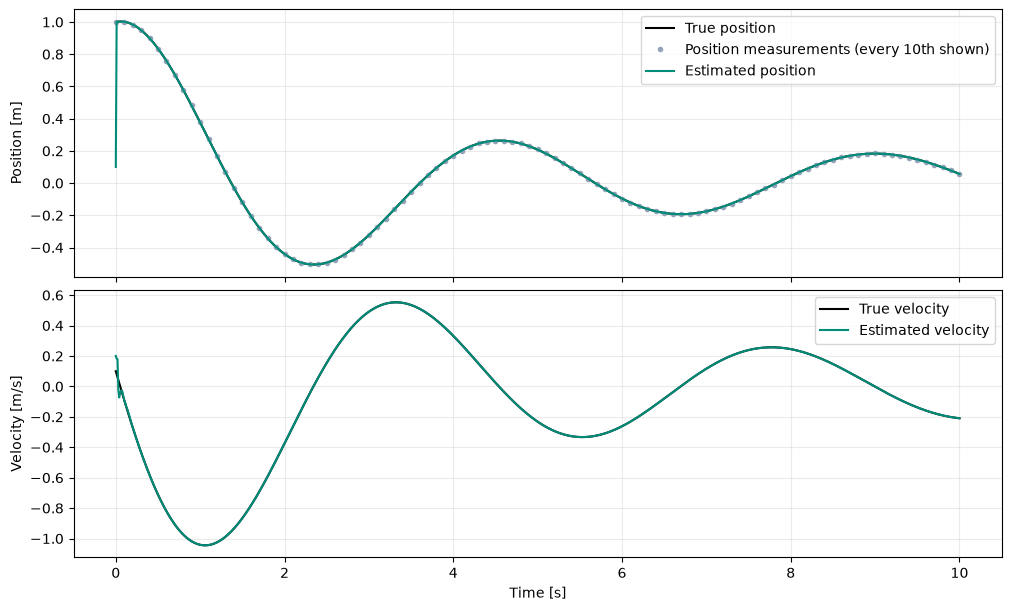

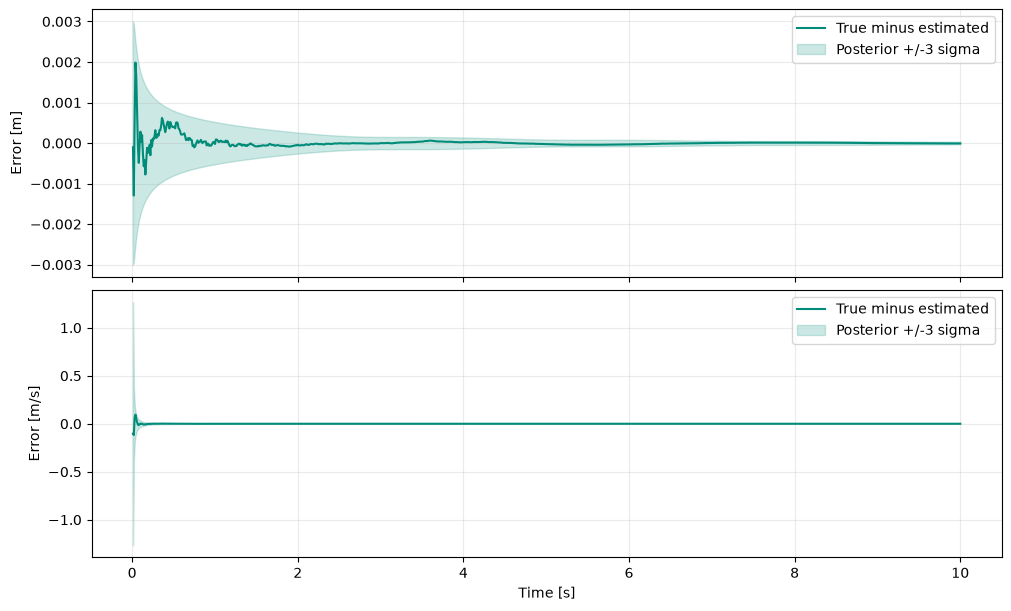

In [14]:
error_state = x - x_hat  # Demo: estimation error relative to truth.
rmse = np.sqrt(np.mean(error_state[:, 1:]**2, axis=1))  # Demo: RMSE after assimilating y_1 onward.
print(f'Position RMSE: {rmse[0]:.6g} m; velocity RMSE: {rmse[1]:.6g} m/s')  # Demo: physical error units.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')  # Tutorial: state reconstruction.
axes[0].plot(t, x[0], color='black', label='True position')  # Demo: true measured state.
axes[0].plot(t[::10], y[0, ::10], '.', color='#94a3b8', label='Position measurements (every 10th shown)')  # Demo: readable observation overlay.
axes[0].plot(t, x_hat[0], color='#008c78', label='Estimated position')  # Paper posterior mean, first component.
axes[0].set_ylabel('Position [m]')  # Tutorial: physical position units.
axes[1].plot(t, x[1], color='black', label='True velocity')  # Demo: unmeasured true state.
axes[1].plot(t, x_hat[1], color='#008c78', label='Estimated velocity')  # Paper posterior mean, second component.
axes[1].set(xlabel='Time [s]', ylabel='Velocity [m/s]')  # Tutorial: physical velocity and time units.
for ax in axes:  # Tutorial: common plot formatting.
    ax.grid(alpha=0.25)  # Tutorial: aid reading of time and state values.
    ax.legend(loc='best')  # Tutorial: identify each curve.
plt.show()  # Tutorial: render state trajectories.

sigma = np.sqrt(np.diagonal(P_history, axis1=1, axis2=2)).T  # Paper covariance: marginal standard deviations.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')  # Tutorial: error and uncertainty.
for ell, units in enumerate(('m', 'm/s')):  # Demo: position and velocity components.
    axes[ell].plot(t[1:], error_state[ell, 1:], color='#008c78', label='True minus estimated')  # Demo: omit the unassimilated initial prior.
    axes[ell].fill_between(t[1:], -3*sigma[ell, 1:], 3*sigma[ell, 1:], alpha=0.2, color='#008c78', label='Posterior +/-3 sigma')  # Model-based uncertainty envelope.
    axes[ell].set_ylabel(f'Error [{units}]')  # Tutorial: state-error units.
    axes[ell].grid(alpha=0.25)  # Tutorial: readable error trajectories.
    axes[ell].legend(loc='best')  # Tutorial: identify error and envelope.
axes[1].set_xlabel('Time [s]')  # Tutorial: common time axis.
plt.show()  # Tutorial: render error diagnostics.


## Numerical validation against the linear Kalman filter

This MSD model and its observation are affine. Thus the sigma-point moments reproduce the linear moments in exact arithmetic. Here $H\mathbf R^v=0$ also makes the paper's one-set measurement moments agree with the standard linear KF. Use an independent KF as a benchmark:
$$\hat{\mathbf x}_k^-=A_d\hat{\mathbf x}_{k-1}+B_du_{k-1},\quad
\mathbf P_k^-=A_d\mathbf P_{k-1}A_d^T+\mathbf R^v,$$
$$\mathbf P_{\tilde y_k\tilde y_k}=H\mathbf P_k^-H^T+\mathbf R^n,\quad
\mathbf P_{x_ky_k}=\mathbf P_k^-H^T.$$
The benchmark uses the Joseph covariance expression to provide a separate numerical check of the subtractive UKF/factor downdate result. The checks compare the entire state and covariance histories, not only the final states, and check positive definiteness and sigma-point reconstruction.


In [15]:
def run_linear_kf(y, u, x_hat0, P0):  # Independent affine-model reference for numerical validation.
    N = y.shape[1]  # Validation: measurement count.
    means = np.empty((L, N))  # Validation: posterior mean history.
    covariances = np.empty((N, L, L))  # Validation: posterior covariance history.
    means[:, 0], covariances[0] = x_hat0, P0  # Reference: same initial prior.
    for k in range(1, N):  # Reference: one update per y_k.
        mean_minus = Ad @ means[:, k-1] + Bd.ravel() * u[k-1]  # Linear prediction.
        P_minus = Ad @ covariances[k-1] @ Ad.T + Rv  # Full predicted covariance.
        P_yy = H @ P_minus @ H.T + Rn  # Innovation covariance, including all process contributions.
        P_xy = P_minus @ H.T  # Linear cross covariance.
        K = np.linalg.solve(P_yy.T, P_xy.T).T  # Solve for the reference Kalman gain.
        means[:, k] = mean_minus + K @ (y[:, k] - H @ mean_minus)  # Posterior mean.
        J = np.eye(L) - K @ H  # Reference Joseph-form residual map.
        covariances[k] = J @ P_minus @ J.T + K @ Rn @ K.T  # Independent positive-semidefinite covariance expression.
    return means, covariances  # Reference histories.

x_kf, P_kf = run_linear_kf(y, u, x_hat0, P0)  # Execute the independent KF benchmark.
mean_gap = np.max(np.abs(x_hat - x_kf))  # Validation: all-time state disagreement.
cov_gap = np.max(np.abs(P_history - P_kf))  # Validation: all-time covariance disagreement.
min_eigenvalue = np.linalg.eigvalsh(P_history).min()  # Validation: smallest posterior covariance eigenvalue.
X0 = sigma_points(x_hat0, np.linalg.cholesky(P0), eta)  # Eq. (6)/(17): initial sigma set.
D0 = X0 - x_hat0[:, None]  # Initial sigma deviations.
np.testing.assert_allclose(X0 @ Wm, x_hat0, atol=1e-14)  # Validate sigma-point mean reconstruction.
np.testing.assert_allclose((D0 * Wc) @ D0.T, P0, atol=1e-14)  # Validate sigma-point covariance reconstruction.
assert np.allclose(H @ Rv, 0.0)  # Validate the one-set timing condition used for this benchmark.
assert np.all(np.isfinite(x_hat)) and np.all(np.isfinite(P_history))  # Require finite filter results.
assert min_eigenvalue > 0.0  # Every stored posterior must be positive definite here.
np.testing.assert_allclose(x_hat, x_kf, rtol=1e-8, atol=2e-9)  # Require agreement with the independent KF.
np.testing.assert_allclose(P_history, P_kf, rtol=1e-7, atol=2e-11)  # Require covariance agreement.
print(f'Max |state - KF|: {mean_gap:.3e}; max |P - KF|: {cov_gap:.3e}')  # Validation evidence.
print(f'Minimum posterior eigenvalue: {min_eigenvalue:.3e}; all KF checks passed.')  # Validation evidence.


Max |state - KF|: 3.214e-12; max |P - KF|: 9.138e-13
Minimum posterior eigenvalue: 1.208e-10; all KF checks passed.


## Interpreting the result and continuing the tutorial

Position is measured; velocity is inferred from the coupling in the state transition. The two-row observability matrix is
$$\mathcal O=\begin{bmatrix}H\\HA_d\end{bmatrix}
=\begin{bmatrix}1&0\\1&T_s\end{bmatrix},$$
with determinant $T_s\ne0$, so both states are observable in this discretized model. The early velocity transient reflects the deliberately different initial mean and the position-only sensor.

The uncertainty bands are $\pm3\sqrt{P_{k,ii}}$ about the estimate under the assumed Gaussian model. They are not deterministic error bounds. The simulated initial truth is fixed, so a single plotted trajectory does not establish statistical consistency. RMSE here excludes the unassimilated initial sample but includes the convergence transient.

Suggested experiments, rerunning from the setup cell:

1. Increase measurement standard deviation `v` by a factor of 10 and observe how the velocity estimate and posterior uncertainty change. `Rn` must change as `v**2`.
2. Change `x_hat0` and `P0` together to compare initial trust with the convergence transient.
3. Change `alpha` using the Section 2 weights. For this affine model, the exact moments do not depend on `alpha`; very small values can increase cancellation in finite precision.
4. Run the companion notebook and compare its RMSE and KF-agreement outputs. Both Python notebooks generate identical inputs and observations from the same random seed. MATLAB's and NumPy's random streams need not be identical across languages.

This linear example demonstrates the algorithm mechanics and factor algebra. It does not establish an accuracy advantage over a linear KF, nonlinear-filter robustness, parameter-estimation behavior, or a runtime speed advantage. State dimension is $L=2$; the state-estimation algorithm is the subject of this tutorial, not the paper's parameter-estimation Algorithm 3.2.


## MATLAB correspondence and how to run

The companion `MSD_UKF.m` is a self-contained script. Its executable lines have comments identifying either the relevant equation or the MSD simulation/plotting role. Run it directly in MATLAB R2016b or later, which supports local functions in scripts.

| Python | MATLAB | Paper |
|---|---|---|
| `np.linalg.cholesky(P)` | `chol(P,'lower')` | Eq. (6), $P=SS^T$ |
| `X_minus @ Wm` | `X_minus*Wm.'` | Eq. (8) |
| `(dX * Wc) @ dX.T + Rv` | `(dX.*repmat(Wc,L,1))*dX.' + Rv` | Eq. (9) |
| `np.linalg.solve(P_yy.T,P_xy.T).T` | `P_xy/P_yy` | Eq. (12) |
| `P_minus - K @ P_yy @ K.T` | `P_minus - K*P_yy*K.'` | Eq. (14) |

Both scripts use the same physical parameters, initial prior, noise model, input, and MATLAB random seed. The variable names `x_hat`, `x_hat_minus`, `Rv`, `Rn`, `P_yy`, and `P_xy` map directly to the paper. Model, storage, and plotting variables are explicitly distinguished from algorithm quantities in the comments.

Python dependencies are NumPy, SciPy, and Matplotlib. Open this file in JupyterLab, Jupyter Notebook, or VS Code and use **Run All**. Each notebook contains all its own definitions; no companion Python module or MATLAB runtime is needed.


## Source and scope

Rudolph van der Merwe and Eric A. Wan, **The Square-Root Unscented Kalman Filter for State and Parameter-Estimation**, supplied as `srukf.pdf`.

Equation numbers refer to that attached four-page paper: Section 2 and Algorithm 2.1 on page 2; Section 3 and Algorithm 3.1 on page 3. The MSD dynamics, simulation values, Euler discretization, plotting, and validation examples are tutorial constructions. Algorithmic equations are transcribed using the paper's symbols; descriptive code aliases identify hats, superscripts, and subscripts that cannot be Python/MATLAB identifiers. The tutorial explains implementation conventions explicitly where indexing or triangular-factor interfaces need clarification.
